In [2]:
!apt-get update
!apt-get install -y libopencv-dev build-essential cmake

Hit:1 https://cli.github.com/packages stable InRelease
Get:2 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Hit:3 http://archive.ubuntu.com/ubuntu noble InRelease
Get:4 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:5 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Get:6 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Get:7 http://archive.ubuntu.com/ubuntu noble-backports InRelease [126 kB]
Get:8 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease [17.8 kB]
Get:9 https://r2u.stat.illinois.edu/ubuntu noble/main amd64 Packages [3,054 kB]
Get:10 http://archive.ubuntu.com/ubuntu noble-updates/multiverse amd64 Packages [67.4 kB]
Get:11 http://archive.ubuntu.com/ubuntu noble-updates/universe amd64 Packages [2,166 kB]
Get:12 http://archive.ubuntu.com/ubuntu noble-updates/main amd64 Packages [1,701 kB]
Get:13 http://archive.ubuntu.com/ubuntu noble-updates/restricted amd64 Packages [2,17

In [13]:
%%writefile main.cpp
#include <iostream>
#include <opencv2/opencv.hpp>
#include <cuda_runtime.h>

int main() {
    std::cout << "OpenCV Versiyonu: " << CV_VERSION << std::endl;

    // Colab GPU Bağlantı Kontrolü
    int deviceCount = 0;
    cudaError_t error = cudaGetDeviceCount(&deviceCount);

    if (error == cudaSuccess && deviceCount > 0) {
        std::cout << "Başarılı! Colab GPU (CUDA) Algılandı. Cihaz Sayısı: " << deviceCount << std::endl;
    } else {
        std::cout << "CUDA Cihazı Bulunamadı veya GPU Aktif Edilmedi!" << std::endl;
    }

    return 0;
}

Overwriting main.cpp


In [14]:
!g++ main.cpp -o app pkg-config --cflags --libs opencv4 -I/usr/local/cuda/include -L/usr/local/cuda/lib64 -lcudart
!./app

g++: error: unrecognized command-line option ‘--cflags’
g++: error: unrecognized command-line option ‘--libs’; did you mean ‘--libs=’?
/bin/bash: line 1: ./app: Permission denied


In [21]:
%%writefile sobel_processing.cpp
#include <iostream>
#include <opencv2/opencv.hpp>

void applySobel(const std::string& imagePath, const std::string& outputPrefix) {
    // 1. Görüntüyü gri tonlamalı (grayscale) olarak yükle
    cv::Mat src = cv::imread(imagePath, cv::IMREAD_GRAYSCALE);
    if (src.empty()) {
        std::cerr << "Hata: Resim yuklenemedi! Yol: " << imagePath << std::endl;
        return;
    }

    // 2. Gürültüyü azaltmak için Gauss Filtresi (Yumuşatma) uygula (3x3 kernel)
    cv::Mat blurred;
    cv::GaussianBlur(src, blurred, cv::Size(3, 3), 0, 0);

    // 3. Sobel Filtrelerini Uygula (3x3 Kernel size)
    cv::Mat grad_x, grad_y;
    cv::Mat abs_grad_x, abs_grad_y;

    // Yatay Gradyan (Sobel X)
    cv::Sobel(blurred, grad_x, CV_16S, 1, 0, 3);
    cv::convertScaleAbs(grad_x, abs_grad_x);

    // Dikey Gradyan (Sobel Y)
    cv::Sobel(blurred, grad_y, CV_16S, 0, 1, 3);
    cv::convertScaleAbs(grad_y, abs_grad_y);

    // 4. Gradyanları Birleştir (Sobel Kenar Algılama)
    cv::Mat grad;
    cv::addWeighted(abs_grad_x, 0.5, abs_grad_y, 0.5, 0, grad);

    // 5. Sonuçları Kaydet
    cv::imwrite(outputPrefix + "_original.jpg", src);
    cv::imwrite(outputPrefix + "_blurred.jpg", blurred);
    cv::imwrite(outputPrefix + "_sobel_x.jpg", abs_grad_x);
    cv::imwrite(outputPrefix + "_sobel_y.jpg", abs_grad_y);
    cv::imwrite(outputPrefix + "_sobel_combined.jpg", grad);

    std::cout << imagePath << " icin Sobel islemleri tamamlandi ve kaydedildi." << std::endl;
}

int main() {
    std::cout << "--- Goruntu Isleme Baslatiliyor ---" << std::endl;
    applySobel("/content/foto1", "foto1");
    applySobel("/content/foto2", "foto2");
    std::cout << "--- Islem Basariyla Tamamlandi ---" << std::endl;
    return 0;
}

Overwriting sobel_processing.cpp


In [22]:
# C++ Kodunu OpenCV ile derle (Backticks ile pkg-config düzeltildi)
!g++ sobel_processing.cpp -o sobel_app `pkg-config --cflags --libs opencv4`

# Programı çalıştır
!chmod +x ./sobel_app
!./sobel_app

--- Goruntu Isleme Baslatiliyor ---
/content/foto1 icin Sobel islemleri tamamlandi ve kaydedildi.
/content/foto2 icin Sobel islemleri tamamlandi ve kaydedildi.
--- Islem Basariyla Tamamlandi ---


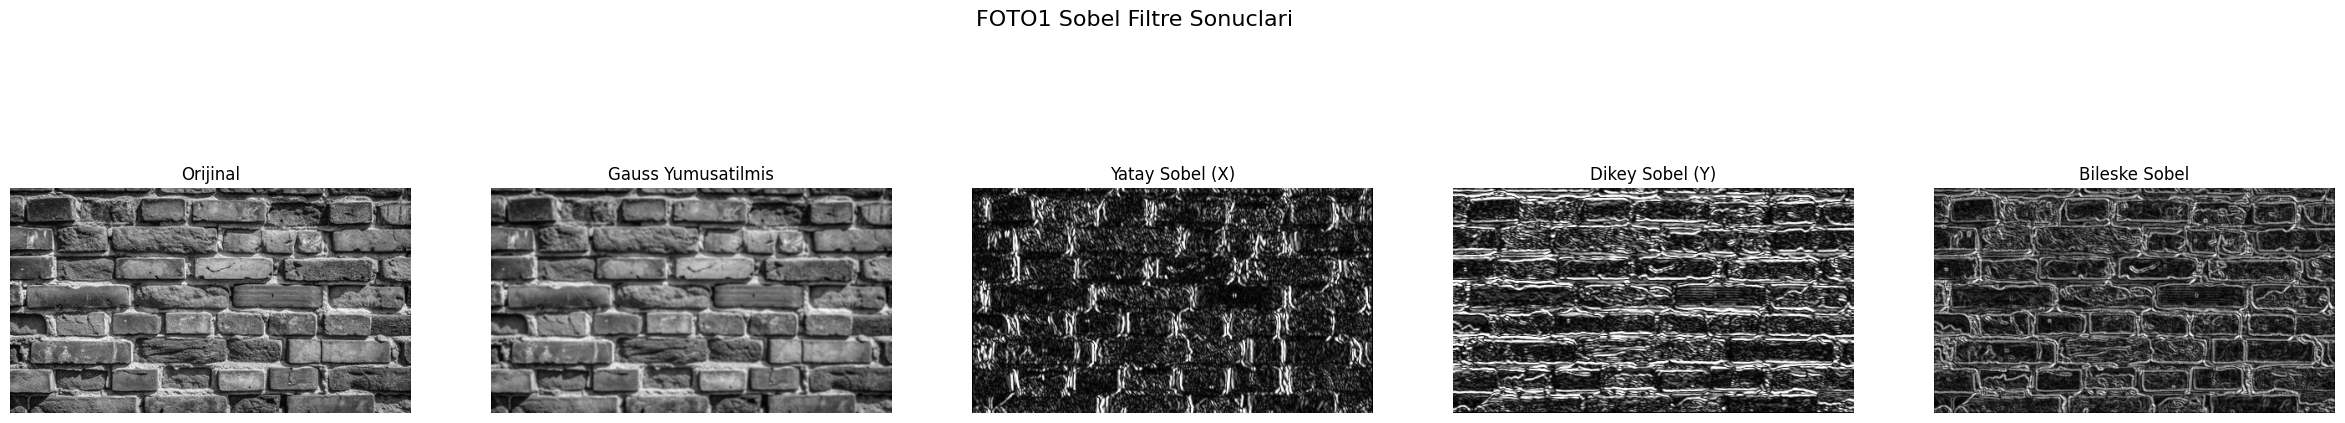

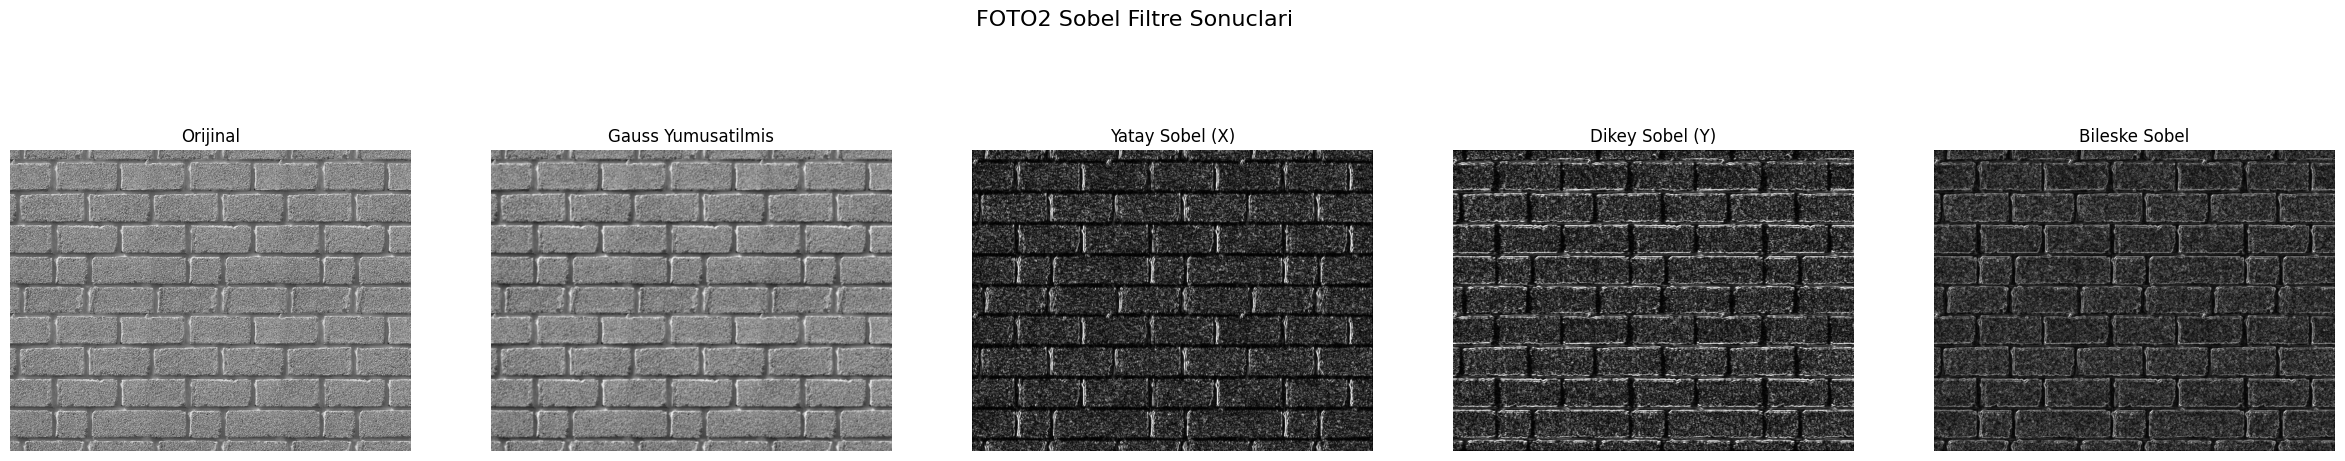

In [23]:
import cv2
import matplotlib.pyplot as plt
import os

def show_results(prefix):
    required_files = [
        f'{prefix}_original.jpg',
        f'{prefix}_blurred.jpg',
        f'{prefix}_sobel_x.jpg',
        f'{prefix}_sobel_y.jpg',
        f'{prefix}_sobel_combined.jpg'
    ]

    for file in required_files:
        if not os.path.exists(file):
            print(f"Hata: '{file}' dosyası bulunamadı! Lütfen C++ kodunun başarıyla derlenip çalıştığından emin olun.")
            return

    fig, axes = plt.subplots(1, 5, figsize=(30, 6))
    original = cv2.imread(f'{prefix}_original.jpg', cv2.IMREAD_GRAYSCALE)
    blurred = cv2.imread(f'{prefix}_blurred.jpg', cv2.IMREAD_GRAYSCALE)
    sobel_x = cv2.imread(f'{prefix}_sobel_x.jpg', cv2.IMREAD_GRAYSCALE)
    sobel_y = cv2.imread(f'{prefix}_sobel_y.jpg', cv2.IMREAD_GRAYSCALE)
    sobel_combined = cv2.imread(f'{prefix}_sobel_combined.jpg', cv2.IMREAD_GRAYSCALE)

    axes[0].imshow(original, cmap='gray')
    axes[0].set_title('Orijinal')
    axes[0].axis('off')

    axes[1].imshow(blurred, cmap='gray')
    axes[1].set_title('Gauss Yumusatilmis')
    axes[1].axis('off')

    axes[2].imshow(sobel_x, cmap='gray')
    axes[2].set_title('Yatay Sobel (X)')
    axes[2].axis('off')

    axes[3].imshow(sobel_y, cmap='gray')
    axes[3].set_title('Dikey Sobel (Y)')
    axes[3].axis('off')

    axes[4].imshow(sobel_combined, cmap='gray')
    axes[4].set_title('Bileske Sobel')
    axes[4].axis('off')

    plt.suptitle(f'{prefix.upper()} Sobel Filtre Sonuclari', fontsize=16)
    plt.show()

show_results('foto1')
show_results('foto2')